# Simple aerodynamic analysis

This notebook contains a simple set of aerodynamic analysis done on some airfoils done using neuralfoil (via the aerosandbox wrapper. Some further analysis tools (Principal Orthogonal Decomposition, FPCA) are tested later on. The goal is simply to illustrate what kind of field analysis can be done using Aerosandbox. 

Operating conditions used: 
- Angle of attack $\alpha$ 0 when nominal, -5, 5 for sweeps
- Reynolds 2e6 when nominal, 2e6 += 1e5 for sweeps

Model used: Neuralfoil (via aerosandbox) with `model_size` parameter set at `xxx_large` 

In [12]:
import aerosandbox as asb
import numpy as np 
from matplotlib import pyplot as plt 

In [13]:
# generate airfoil 
airfoil = asb.Airfoil("NACA0006")
# airfoil.draw(backend="matplotlib")

# generate aerodynamimc fields 
_grid_res = 50
alpha = 0
reynold = 2e6
alphas = np.linspace(-5, 5, _grid_res)
reynolds = np.linspace(reynold - 1e5, reynold + 1e5, _grid_res)

## for field 
a_batch, re_batch = np.meshgrid(alphas, reynolds)

## different sweeps 
alpha_sweep = airfoil.get_aero_from_neuralfoil(alpha=alphas, Re=reynold, model_size="xxxlarge")
re_sweep = airfoil.get_aero_from_neuralfoil(alpha=alpha, Re=reynold, model_size='xxxlarge')

## aerodynamic field 
aero_fields = airfoil.get_aero_from_neuralfoil(alpha=a_batch.flatten(), Re=re_batch.flatten(), model_size="xxxlarge")

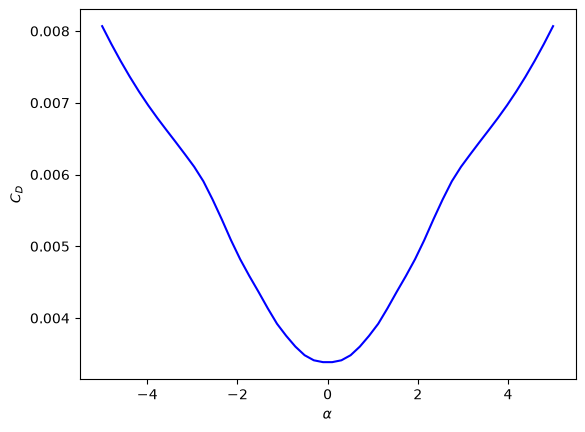

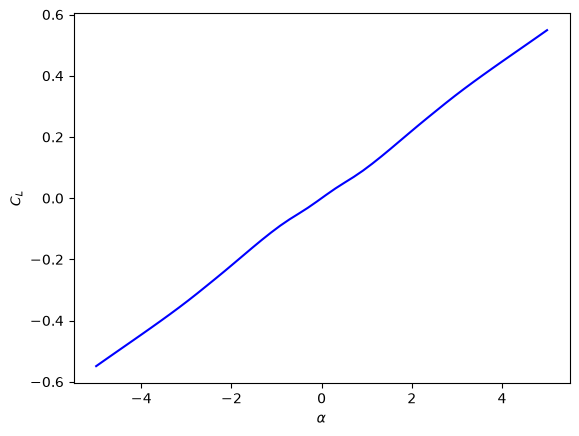

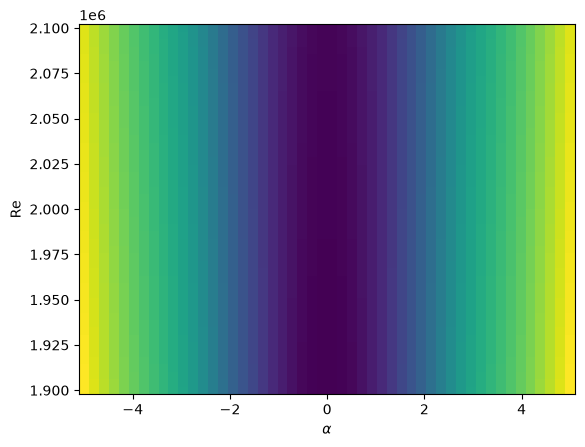

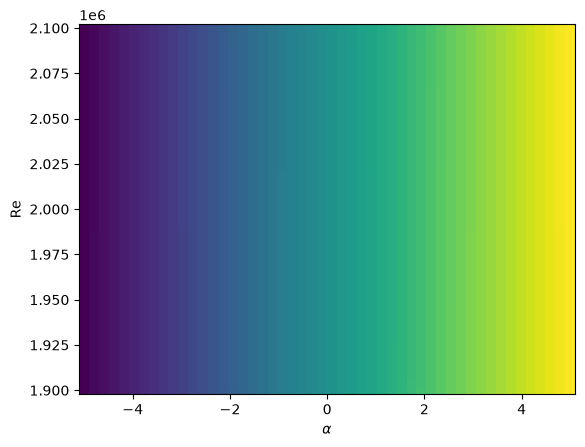

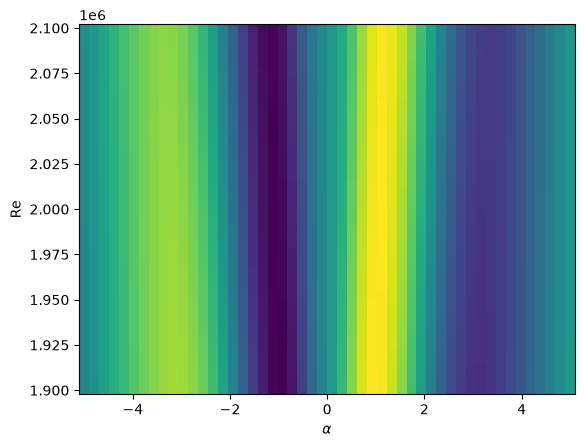

In [14]:
## alpha and Re sweep plots 
## CD 
plt.plot(alphas, alpha_sweep["CD"], linestyle='-', color='blue') 
plt.xlabel("$\\alpha$")
plt.ylabel("$C_D$")
plt.show()

## CL 
plt.plot(alphas, alpha_sweep["CL"], linestyle='-', color='blue') 
plt.xlabel("$\\alpha$")
plt.ylabel("$C_L$")
plt.show() 

## Field plots
plt.pcolormesh(a_batch, re_batch, aero_fields["CD"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.show()

plt.pcolormesh(a_batch, re_batch, aero_fields["CL"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.show()

plt.pcolormesh(a_batch, re_batch, aero_fields["CM"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.show()

# POD of the aerodynamic fields 

Proper Orthogonal decomposition is one of the first field reduction methods that are used in this project. The next section displays a simple manner of how to apply the technique to an aerodynamic field using Python. 